# PH3043 — Independent Dataset Validation

## Notebook 03: SingleMu–DoubleMu Comparison

### Objective

To evaluate whether the detector-region dependence observed
in the SingleMu 2011 educational dataset reproduces in a
second CERN CMS dimuon dataset.

### Research questions

1. Do the two datasets contain overlapping collision events?
2. Are their kinematic and detector-region distributions similar?
3. Does the regional resonance-center difference reproduce?
4. How sensitive are the results to common event-selection
   and resonance-model assumptions?

### Scientific safeguards

- Reconstruct invariant mass independently.
- Identify overlapping collision events using Run and Event.
- Avoid treating overlapping records as independent.
- Apply predefined, comparable analysis procedures.
- Report null, inconsistent and unsuccessful results.

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Inspect available files before selecting
for path in sorted(DATA_DIR.glob("*.csv")):
    print(path.name)

# Update the filename if your CERN download differs
doublemu_file = DATA_DIR / "Dimuon_DoubleMu.csv"

assert doublemu_file.exists(), (
    f"Dataset not found: {doublemu_file}"
)

df_double = pd.read_csv(doublemu_file)

print("\nDoubleMu dataset shape:", df_double.shape)
print("\nColumns:")
print(df_double.columns.tolist())

display(df_double.head())

print("\nMissing values:")
print(df_double.isna().sum())


Dimuon_DoubleMu.csv
Dimuon_SingleMu.csv

DoubleMu dataset shape: (100000, 21)

Columns:
['Run', 'Event', 'type1', 'E1', 'px1', 'py1', 'pz1', 'pt1', 'eta1', 'phi1', 'Q1', 'type2', 'E2', 'px2', 'py2', 'pz2', 'pt2', 'eta2', 'phi2', 'Q2', 'M']


,Run,Event,type1,E1,px1,py1,pz1,pt1,eta1,phi1,...,type2,E2,px2,py2,pz2,pt2,eta2,phi2,Q2,M
0,165617,74601703,G,9.6987,-9.5104,0.3662,1.8633,9.5175,0.1945,3.1031,...,G,9.7633,7.3277,-1.1524,6.3473,7.4178,0.7756,-0.1560,1,17.4922
1,165617,75100943,G,6.2039,-4.2666,0.4565,-4.4793,4.2910,-0.9121,3.0350,...,G,9.6690,7.2740,-2.8211,-5.7104,7.8019,-0.6786,-0.3700,1,11.5534
2,165617,75587682,G,19.2892,-4.2121,-0.6516,18.8121,4.2622,2.1905,-2.9881,...,G,9.8244,4.3439,-0.4735,8.7985,4.3697,1.4497,-0.1086,1,9.1636
3,165617,75660978,G,7.0427,-6.3268,-0.2685,3.0802,6.3325,0.4690,-3.0992,...,G,5.5857,4.4748,0.8489,-3.2319,4.5546,-0.6605,0.1875,1,12.4774
4,165617,75947690,G,7.2751,0.1030,-5.5331,-4.7212,5.5340,-0.7736,-1.5522,...,G,7.3181,-0.3988,6.9408,2.2825,6.9523,0.3227,1.6282,1,14.3159



Missing values:
Run      0
Event    0
type1    0
E1       0
px1      0
py1      0
pz1      0
pt1      0
eta1     0
phi1     0
Q1       0
type2    0
E2       0
px2      0
py2      0
pz2      0
pt2      0
eta2     0
phi2     0
Q2       0
M        0
dtype: int64


In [2]:
#check for overlapping collusion events

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Inspect available files before selecting
for path in sorted(DATA_DIR.glob("*.csv")):
    print(path.name)

# Update the filename if your CERN download differs
doublemu_file = DATA_DIR / "Dimuon_DoubleMu.csv"

assert doublemu_file.exists(), (
    f"Dataset not found: {doublemu_file}"
)

df_double = pd.read_csv(doublemu_file)

print("\nDoubleMu dataset shape:", df_double.shape)
print("\nColumns:")
print(df_double.columns.tolist())

display(df_double.head())

print("\nMissing values:")
print(df_double.isna().sum())


Dimuon_DoubleMu.csv
Dimuon_SingleMu.csv

DoubleMu dataset shape: (100000, 21)

Columns:
['Run', 'Event', 'type1', 'E1', 'px1', 'py1', 'pz1', 'pt1', 'eta1', 'phi1', 'Q1', 'type2', 'E2', 'px2', 'py2', 'pz2', 'pt2', 'eta2', 'phi2', 'Q2', 'M']


,Run,Event,type1,E1,px1,py1,pz1,pt1,eta1,phi1,...,type2,E2,px2,py2,pz2,pt2,eta2,phi2,Q2,M
0,165617,74601703,G,9.6987,-9.5104,0.3662,1.8633,9.5175,0.1945,3.1031,...,G,9.7633,7.3277,-1.1524,6.3473,7.4178,0.7756,-0.1560,1,17.4922
1,165617,75100943,G,6.2039,-4.2666,0.4565,-4.4793,4.2910,-0.9121,3.0350,...,G,9.6690,7.2740,-2.8211,-5.7104,7.8019,-0.6786,-0.3700,1,11.5534
2,165617,75587682,G,19.2892,-4.2121,-0.6516,18.8121,4.2622,2.1905,-2.9881,...,G,9.8244,4.3439,-0.4735,8.7985,4.3697,1.4497,-0.1086,1,9.1636
3,165617,75660978,G,7.0427,-6.3268,-0.2685,3.0802,6.3325,0.4690,-3.0992,...,G,5.5857,4.4748,0.8489,-3.2319,4.5546,-0.6605,0.1875,1,12.4774
4,165617,75947690,G,7.2751,0.1030,-5.5331,-4.7212,5.5340,-0.7736,-1.5522,...,G,7.3181,-0.3988,6.9408,2.2825,6.9523,0.3227,1.6282,1,14.3159



Missing values:
Run      0
Event    0
type1    0
E1       0
px1      0
py1      0
pz1      0
pt1      0
eta1     0
phi1     0
Q1       0
type2    0
E2       0
px2      0
py2      0
pz2      0
pt2      0
eta2     0
phi2     0
Q2       0
M        0
dtype: int64


## 2. Independent-Sample Preparation

The DoubleMu dataset is compared with the previously
analyzed SingleMu dataset using unique collision identifiers.

Overlapping events are excluded to avoid reusing the same
collision records in the replication analysis.

Invariant masses are then independently reconstructed from
transverse momentum, pseudorapidity and azimuthal angle.

The supplied CERN mass column is reserved for validation.

In [10]:

# Identify overlapping events between the two datasets

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Load both original datasets
df_single = pd.read_csv(
    DATA_DIR / "Dimuon_SingleMu.csv"
)

df_double = pd.read_csv(
    DATA_DIR / "Dimuon_DoubleMu.csv"
)

# Identify unique collision records
single_ids = df_single[
    ["Run", "Event"]
].drop_duplicates()

double_ids = df_double[
    ["Run", "Event"]
].drop_duplicates()

# Find shared collision identifiers
overlap = single_ids.merge(
    double_ids,
    on=["Run", "Event"],
    how="inner"
)

print("SingleMu records:", len(df_single))
print("DoubleMu records:", len(df_double))
print("Overlapping events:", len(overlap))

# Keep DoubleMu records absent from SingleMu
double_unique = df_double.merge(
    single_ids,
    on=["Run", "Event"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

double_unique = (
    double_unique.loc[
        double_unique["_merge"] == "left_only"
    ]
    .drop(columns="_merge")
    .copy()
)

print(
    "Nonoverlapping DoubleMu records:",
    len(double_unique)
)


SingleMu records: 83761
DoubleMu records: 100000
Overlapping events: 99
Nonoverlapping DoubleMu records: 99901


In [12]:


# Prepare a nonoverlapping DoubleMu analysis sample

import numpy as np
import pandas as pd

# Start with the DoubleMu rows absent from SingleMu
df_rep = double_unique.copy()

# Muon mass in GeV, natural units
m_mu = 0.105658

# Reconstruct each muon's four-momentum
for i in [1, 2]:

    pt = df_rep[f"pt{i}"]
    eta = df_rep[f"eta{i}"]
    phi = df_rep[f"phi{i}"]

    df_rep[f"px{i}_reco"] = pt * np.cos(phi)
    df_rep[f"py{i}_reco"] = pt * np.sin(phi)
    df_rep[f"pz{i}_reco"] = pt * np.sinh(eta)

    df_rep[f"E{i}_reco"] = np.sqrt(
        pt**2 * np.cosh(eta)**2 + m_mu**2
    )

# Combine the two four-momenta
E = df_rep["E1_reco"] + df_rep["E2_reco"]
px = df_rep["px1_reco"] + df_rep["px2_reco"]
py = df_rep["py1_reco"] + df_rep["py2_reco"]
pz = df_rep["pz1_reco"] + df_rep["pz2_reco"]

M2 = E**2 - px**2 - py**2 - pz**2

# Flag nonphysical or nonfinite results
valid_mass = np.isfinite(M2) & (M2 >= 0)

df_rep["M_reconstructed"] = np.where(
    valid_mass,
    np.sqrt(np.maximum(M2, 0)),
    np.nan
)

# Independently compare with CERN's stored mass
df_rep["M_difference"] = abs(
    df_rep["M_reconstructed"] - df_rep["M"]
)

# Reuse the predefined detector-region categories
df_rep["max_abs_eta"] = np.maximum(
    abs(df_rep["eta1"]),
    abs(df_rep["eta2"])
)

df_rep["region"] = np.where(
    df_rep["max_abs_eta"] < 1.2,
    "Central-central",
    "Forward-containing"
)

print("Nonoverlapping DoubleMu records:", len(df_rep))
print("Valid reconstructed masses:",
      df_rep["M_reconstructed"].notna().sum())

print("\nMass validation:")
print(df_rep["M_difference"].describe())

print("\nDetector-region counts:")
print(df_rep["region"].value_counts())

print("\nEvents in the baseline fit window:")
in_window = df_rep["M_reconstructed"].between(
    85, 97.5, inclusive="left"
)

print(df_rep.loc[in_window, "region"].value_counts())


Nonoverlapping DoubleMu records: 99901
Valid reconstructed masses: 99901

Mass validation:
count    9.990100e+04
mean     2.333626e-02
std      5.070819e-01
min      4.722267e-11
25%      6.176090e-05
50%      1.579679e-04
75%      3.875079e-04
max      7.164169e+01
Name: M_difference, dtype: float64

Detector-region counts:
region
Forward-containing    54569
Central-central       45332
Name: count, dtype: int64

Events in the baseline fit window:
region
Forward-containing    2802
Central-central       1854
Name: count, dtype: int64


## 3. Replication of Detector-Region Resonance Fits

The central-versus-forward resonance-center comparison
is repeated on the nonoverlapping DoubleMu sample.

The same mass reconstruction, event categories, fit window,
bin width and Voigt-plus-exponential model are used as
in the original SingleMu analysis.

All six fitting parameters are reoptimized independently
for the two DoubleMu categories.

The objective is to test whether the original regional
difference can be reproduced in a different event sample.

In [15]:

import numpy as np
import pandas as pd

from scipy.optimize import minimize
from scipy.special import voigt_profile, gammaln
from numpy.polynomial.legendre import leggauss

# Baseline settings
edges = np.arange(85, 98, 0.5)
centers = (edges[:-1] + edges[1:]) / 2

nodes, weights = leggauss(16)

half = np.diff(edges) / 2
mid = (edges[:-1] + edges[1:]) / 2

points = mid[:, None] + half[:, None] * nodes

# Parameter order:
# S, m0, gamma, sigma, B0, k
scales = np.array([10000, 1, 1, 1, 100, 0.1])

bounds = [
    (100, 50000),
    (85, 98),
    (0.2, 5),
    (0.05, 5),
    (0, 1000),
    (-0.5, 0.5)
]

scaled_bounds = [
    (lo / s, hi / s)
    for (lo, hi), s in zip(bounds, scales)
]

def expected_doublemu(params):
    S, m0, gamma, sigma, B0, k = params

    signal = (
        S * half *
        np.sum(
            weights * voigt_profile(
                points - m0, sigma, gamma
            ),
            axis=1
        )
    )

    background = (
        half *
        np.sum(
            weights * (B0 / 0.5)
            * np.exp(k * (points - 91)),
            axis=1
        )
    )

    return signal + background


def fit_doublemu_region(region):

    mass = df_rep.loc[
        df_rep["region"] == region,
        "M_reconstructed"
    ].dropna().to_numpy()

    counts, _ = np.histogram(
        mass, bins=edges
    )

    def nll(z):
        mu = expected_doublemu(z * scales)

        if np.any(~np.isfinite(mu)) or np.any(mu <= 0):
            return 1e100

        return np.sum(
            mu - counts * np.log(mu)
            + gammaln(counts + 1)
        )

    solutions = []

    # Different plausible initial conditions
    for center0 in [90.5, 91.0, 91.5]:
        for sigma0 in [0.8, 1.5, 2.2]:

            initial = np.array([
                3000,
                center0,
                1.2,
                sigma0,
                50,
                -0.15
            ])

            result = minimize(
                nll,
                initial / scales,
                method="L-BFGS-B",
                bounds=scaled_bounds,
                options={
                    "maxiter": 20000,
                    "ftol": 1e-12,
                    "maxls": 50
                }
            )

            if result.success and np.isfinite(result.fun):
                solutions.append(result)

    if not solutions:
        raise RuntimeError(
            f"No converged fit for {region}"
        )

    best = min(solutions, key=lambda x: x.fun)

    params = best.x * scales
    predicted = expected_doublemu(params)

    positive = counts > 0
    term = np.zeros_like(counts, dtype=float)

    term[positive] = (
        counts[positive] *
        np.log(counts[positive] / predicted[positive])
    )

    deviance = 2 * np.sum(
        term - (counts - predicted)
    )

    dof = len(counts) - len(params)

    return {
        "params": params,
        "observed": counts,
        "predicted": predicted,
        "nll": best.fun,
        "deviance_dof": deviance / dof,
        "events": int(counts.sum())
    }


doublemu_results = {}
summary = []

for region in [
    "Central-central",
    "Forward-containing"
]:

    result = fit_doublemu_region(region)

    doublemu_results[region] = result

    p = result["params"]

    summary.append({
        "Region": region,
        "Events": result["events"],
        "Center (GeV)": p[1],
        "Gamma (GeV)": p[2],
        "Sigma (GeV)": p[3],
        "Background slope": p[5],
        "Deviance/dof": result["deviance_dof"]
    })

doublemu_summary = pd.DataFrame(summary)

display(doublemu_summary.round(5))

central = doublemu_results["Central-central"]["params"][1]
forward = doublemu_results["Forward-containing"]["params"][1]

print(
    "\nDoubleMu regional difference:",
    round(1000 * (central - forward), 3),
    "MeV"
)

print("SingleMu difference: 165.932 MeV")


,Region,Events,Center (GeV),Gamma (GeV),Sigma (GeV),Background slope,Deviance/dof
0,Central-central,1854,90.87434,1.12104,1.19723,-0.16761,0.79941
1,Forward-containing,2802,90.85849,1.31386,1.26714,-0.21691,0.76542



DoubleMu regional difference: 15.843 MeV
SingleMu difference: 165.932 MeV


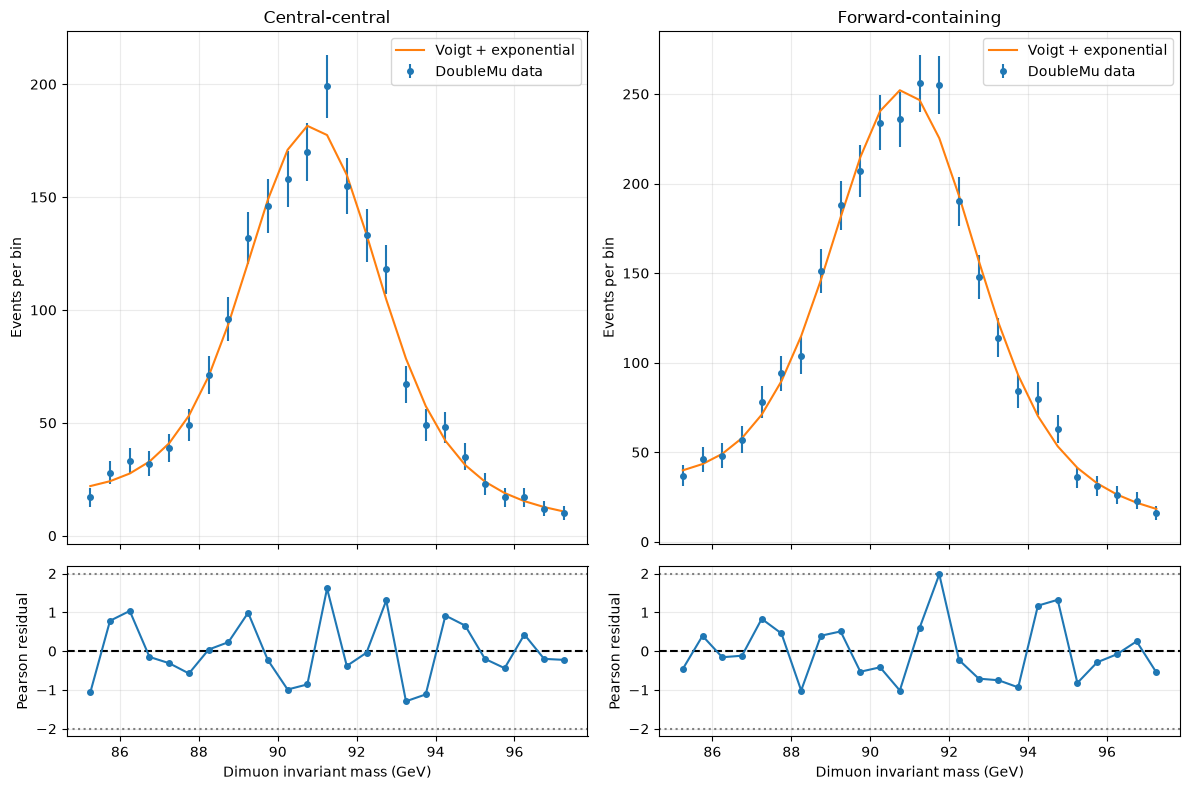

In [16]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharex="col",
    gridspec_kw={"height_ratios": [3, 1]}
)

regions = [
    "Central-central",
    "Forward-containing"
]

for j, region in enumerate(regions):

    result = doublemu_results[region]

    observed = result["observed"]
    predicted = result["predicted"]

    residuals = (
        (observed - predicted)
        / np.sqrt(np.maximum(predicted, 1e-12))
    )

    axes[0, j].errorbar(
        centers,
        observed,
        yerr=np.sqrt(np.maximum(observed, 1)),
        fmt="o",
        markersize=4,
        label="DoubleMu data"
    )

    axes[0, j].plot(
        centers,
        predicted,
        label="Voigt + exponential"
    )

    axes[0, j].set_title(region)
    axes[0, j].set_ylabel("Events per bin")
    axes[0, j].legend()
    axes[0, j].grid(alpha=0.25)

    axes[1, j].axhline(
        0, color="black", linestyle="--"
    )

    axes[1, j].axhline(
        2, color="gray", linestyle=":"
    )

    axes[1, j].axhline(
        -2, color="gray", linestyle=":"
    )

    axes[1, j].plot(
        centers,
        residuals,
        "o-",
        markersize=4
    )

    axes[1, j].set_xlabel(
        "Dimuon invariant mass (GeV)"
    )

    axes[1, j].set_ylabel("Pearson residual")
    axes[1, j].grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 4. Reconstruction-Category Composition

The SingleMu and nonoverlapping DoubleMu datasets have
different proportions of global and tracker muons.

To investigate whether this contributes to differences
in their reconstructed resonance centers, the event
composition is compared before fitting.

A G-G-only sensitivity analysis will be performed
using the same predefined detector regions and
resonance-fitting procedure.

In [22]:

# Load SingleMu analysis data from Notebook 02
# and use DoubleMu data already prepared in Notebook 03

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd().resolve().parent

single_file = (
    PROJECT_ROOT
    / "results"
    / "dimuon_reconstructed.csv"
)

if not single_file.exists():
    raise FileNotFoundError(
        f"SingleMu analysis file not found: {single_file}"
    )

# SingleMu: previously reconstructed in Notebook 01
single = pd.read_csv(single_file)

# DoubleMu: reconstructed in Notebook 03
double = df_rep.copy()

print("SingleMu records:", len(single))
print("DoubleMu records:", len(double))

print("\nSingleMu columns:")
print(single.columns.tolist())


SingleMu records: 83761
DoubleMu records: 99901

SingleMu columns:
['Run', 'Event', 'Q1', 'Q2', 'pt1', 'eta1', 'phi1', 'pt2', 'eta2', 'phi2', 'M', 'M_calc', 'M_alt_corrected', 'M_diff', 'M_alt_corrected_diff', 'pt1_diff', 'pt2_diff']


In [30]:


# Prepare SingleMu for cross-dataset comparison

# df_single was loaded in Cell 5
single = df_single.copy()
double = df_rep.copy()

m_mu = 0.105658  # GeV, natural units

# Reconstruct SingleMu four-momenta
for i in [1, 2]:
    pt = single[f"pt{i}"]
    eta = single[f"eta{i}"]
    phi = single[f"phi{i}"]

    single[f"px{i}_reco"] = pt * np.cos(phi)
    single[f"py{i}_reco"] = pt * np.sin(phi)
    single[f"pz{i}_reco"] = pt * np.sinh(eta)

    single[f"E{i}_reco"] = np.sqrt(
        (pt * np.cosh(eta))**2 + m_mu**2
    )

E = single["E1_reco"] + single["E2_reco"]
px = single["px1_reco"] + single["px2_reco"]
py = single["py1_reco"] + single["py2_reco"]
pz = single["pz1_reco"] + single["pz2_reco"]

mass2 = E**2 - px**2 - py**2 - pz**2

single["M_alt_corrected"] = np.sqrt(
    mass2.where(np.isfinite(mass2) & (mass2 >= 0))
)

# Recreate the same regional categories
single["max_abs_eta"] = np.maximum(
    single["eta1"].abs(),
    single["eta2"].abs()
)

single["region"] = np.where(
    single["max_abs_eta"] < 1.2,
    "Central-central",
    "Forward-containing"
)

print("SingleMu rows:", len(single))
print("Valid SingleMu masses:",
      single["M_alt_corrected"].notna().sum())
print("DoubleMu rows:", len(double))


SingleMu rows: 83761
Valid SingleMu masses: 83761
DoubleMu rows: 99901


In [32]:

# Inspect reconstruction-type combinations

print("SingleMu reconstruction types:")
display(pd.crosstab(single["type1"], single["type2"]))

print("DoubleMu reconstruction types:")
display(pd.crosstab(double["type1"], double["type2"]))

# Create reconstruction-category labels
def classify_pair(data):
    result = data.copy()

    pair = (
        result["type1"].astype(str)
        + "-"
        + result["type2"].astype(str)
    )

    result["pair_type"] = pair.replace({
        "T-G": "G-T"
    })

    return result

single = classify_pair(single)
double = classify_pair(double)

# Compare the overall composition
summary = pd.DataFrame({
    "SingleMu": single["pair_type"].value_counts(),
    "DoubleMu": double["pair_type"].value_counts()
}).fillna(0).astype(int)

summary["SingleMu_%"] = (
    100 * summary["SingleMu"] / len(single)
)

summary["DoubleMu_%"] = (
    100 * summary["DoubleMu"] / len(double)
)

display(summary.round(2))


SingleMu reconstruction types:


type2,G,T
type1,,
G,34742,49019


DoubleMu reconstruction types:


type2,G,T
type1,,
G,93379,6522


,SingleMu,DoubleMu,SingleMu_%,DoubleMu_%
pair_type,,,,
G-G,34742,93379,41.48,93.47
G-T,49019,6522,58.52,6.53


In [34]:

# Examine reconstruction types within the Z fit window

single_z = single.loc[
    single["M_alt_corrected"].between(
        85, 97.5, inclusive="left"
    )
]

double_z = double.loc[
    double["M_reconstructed"].between(
        85, 97.5, inclusive="left"
    )
]

print("SingleMu — resonance window")
display(
    pd.crosstab(
        single_z["region"],
        single_z["pair_type"],
        margins=True
    )
)

print("\nDoubleMu — resonance window")
display(
    pd.crosstab(
        double_z["region"],
        double_z["pair_type"],
        margins=True
    )
)

print("\nReconstruction-category percentages:")

for name, data in [
    ("SingleMu", single_z),
    ("DoubleMu", double_z)
]:
    print(f"\n{name}")

    percentages = pd.crosstab(
        data["region"],
        data["pair_type"],
        normalize="index"
    ) * 100

    display(percentages.round(2))


SingleMu — resonance window


pair_type,G-G,G-T,All
region,,,
Central-central,3962,111,4073
Forward-containing,5969,137,6106
All,9931,248,10179



DoubleMu — resonance window


pair_type,G-G,G-T,All
region,,,
Central-central,1828,26,1854
Forward-containing,2762,40,2802
All,4590,66,4656



Reconstruction-category percentages:

SingleMu


pair_type,G-G,G-T
region,,
Central-central,97.27,2.73
Forward-containing,97.76,2.24



DoubleMu


pair_type,G-G,G-T
region,,
Central-central,98.60,1.40
Forward-containing,98.57,1.43


## 5. G-G-Only Controlled Resonance Comparison

### Objective

To investigate whether differences in muon reconstruction
categories contribute to the disagreement between SingleMu
and DoubleMu regional resonance-center estimates.

### Method

Both datasets are restricted to events in which both muons
are reconstructed as global muons (G-G).

The original pseudorapidity categories, invariant-mass
reconstruction, Voigt-plus-exponential model, Poisson
likelihood, fitting window and bin width are preserved.

### Hypothesis

If G-T event composition substantially contributes to
the discrepancy between datasets, restricting both
datasets to G-G events may reduce that discrepancy.

The resulting mass differences will be compared with
the unrestricted baseline estimates.

In [37]:

# Section 5: G-G-only sensitivity analysis

from scipy.optimize import minimize
from scipy.special import gammaln
import numpy as np
import pandas as pd

regions = ["Central-central", "Forward-containing"]

def fit_selected_sample(data, mass_column, region):

    # Select global-global muon events
    mask = (
        (data["region"] == region) &
        (data["pair_type"] == "G-G")
    )

    masses = data.loc[
        mask, mass_column
    ].dropna().to_numpy()

    # Same bin edges as the original analysis
    observed, _ = np.histogram(masses, bins=edges)

    # Same Voigt + exponential model
    def nll(z):
        params = z * scales
        predicted = expected_doublemu(params)

        if (
            np.any(~np.isfinite(predicted)) or
            np.any(predicted <= 0)
        ):
            return 1e100

        return np.sum(
            predicted
            - observed * np.log(predicted)
            + gammaln(observed + 1)
        )

    solutions = []

    # Use multiple starting values
    for center0 in [90.5, 91.0, 91.5]:
        for sigma0 in [0.8, 1.2, 1.8]:

            initial = np.array([
                3000,
                center0,
                1.2,
                sigma0,
                50,
                -0.15
            ])

            result = minimize(
                nll,
                initial / scales,
                method="L-BFGS-B",
                bounds=scaled_bounds,
                options={
                    "maxiter": 20000,
                    "ftol": 1e-12,
                    "maxls": 50
                }
            )

            if result.success and np.isfinite(result.fun):
                solutions.append(result)

    if not solutions:
        raise RuntimeError(
            f"No converged fit for {region}"
        )

    best = min(solutions, key=lambda r: r.fun)

    params = best.x * scales
    predicted = expected_doublemu(params)

    positive = observed > 0
    term = np.zeros_like(observed, dtype=float)

    term[positive] = (
        observed[positive] *
        np.log(observed[positive] / predicted[positive])
    )

    deviance = 2 * np.sum(
        term - (observed - predicted)
    )

    dof = len(observed) - len(params)

    return {
        "center": params[1],
        "gamma": params[2],
        "sigma": params[3],
        "deviance_dof": deviance / dof,
        "events": int(observed.sum()),
        "params": params,
        "nll": best.fun
    }


# Run the controlled comparison
gg_results = []
gg_fits = {}

datasets = {
    "SingleMu": (single, "M_alt_corrected"),
    "DoubleMu": (double, "M_reconstructed")
}

for dataset_name, (data, mass_col) in datasets.items():

    gg_fits[dataset_name] = {}

    for region in regions:

        result = fit_selected_sample(
            data, mass_col, region
        )

        gg_fits[dataset_name][region] = result

        gg_results.append({
            "Dataset": dataset_name,
            "Region": region,
            "Events": result["events"],
            "Center (GeV)": result["center"],
            "Gamma (GeV)": result["gamma"],
            "Sigma (GeV)": result["sigma"],
            "Deviance/dof": result["deviance_dof"]
        })

gg_summary = pd.DataFrame(gg_results)

display(gg_summary.round(5))


,Dataset,Region,Events,Center (GeV),Gamma (GeV),Sigma (GeV),Deviance/dof
0,SingleMu,Central-central,3962,90.98589,1.21934,1.01999,1.06232
1,SingleMu,Forward-containing,5969,90.81272,0.76234,1.56454,0.67430
2,DoubleMu,Central-central,1828,90.86961,1.13964,1.18988,0.86698
3,DoubleMu,Forward-containing,2762,90.86076,1.28954,1.28613,0.72643


In [39]:

# Compare G-G-only regional differences

comparison = []

baseline_differences = {
    "SingleMu": 0.165932,
    "DoubleMu": 0.015843
}

for dataset_name in datasets:

    central = gg_fits[
        dataset_name
    ]["Central-central"]["center"]

    forward = gg_fits[
        dataset_name
    ]["Forward-containing"]["center"]

    gg_difference = central - forward

    baseline_difference = baseline_differences[dataset_name]

    comparison.append({
        "Dataset": dataset_name,
        "Baseline difference (MeV)": (
            baseline_difference * 1000
        ),
        "G-G only difference (MeV)": (
            gg_difference * 1000
        ),
        "Change (MeV)": (
            (gg_difference - baseline_difference) * 1000
        )
    })

gg_comparison = pd.DataFrame(comparison)

display(gg_comparison.round(3))


,Dataset,Baseline difference (MeV),G-G only difference (MeV),Change (MeV)
0,SingleMu,165.932,173.165,7.233
1,DoubleMu,15.843,8.855,-6.988


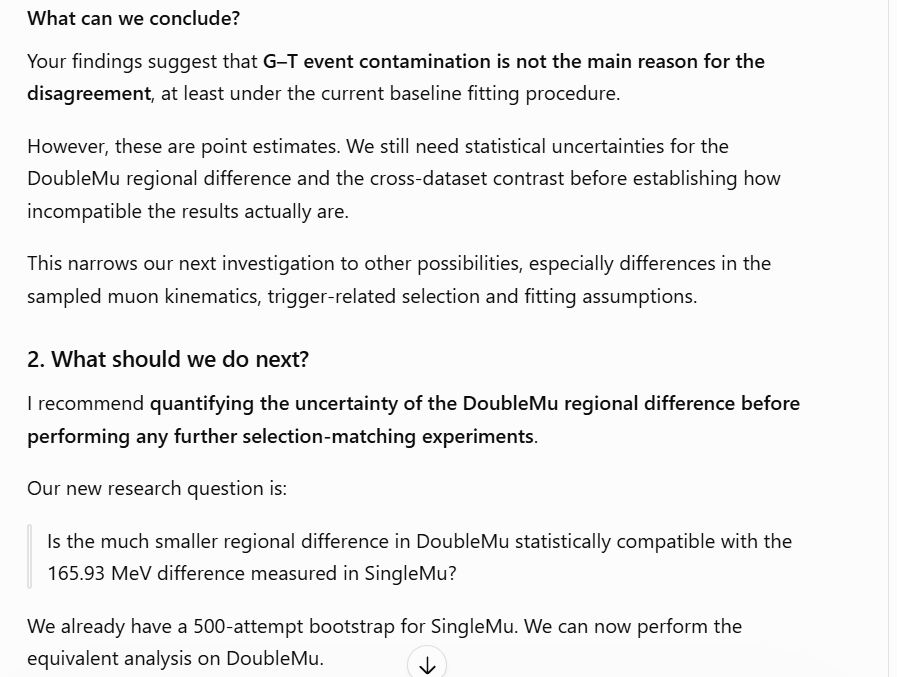

## 6. Bootstrap Validation of the DoubleMu Regional Difference

### Objective

Estimate the sampling uncertainty of the central-minus-forward
resonance-center difference in the nonoverlapping DoubleMu sample.

### Method

A nonparametric bootstrap is performed independently within
each detector-region category.

For every resample, the Voigt-plus-exponential model is refitted
using the original 85–97.5 GeV fitting window and 0.5 GeV bins.

The resulting confidence interval will be compared with the
corresponding SingleMu result.

### Limitation

The bootstrap quantifies statistical sampling variability
conditional on the adopted model and event selection.
It does not include detector-calibration or model-systematic
uncertainties.

Successful fits: 300
Failed fits: 0

Observed difference (MeV): 15.842838000551751
Bootstrap mean (MeV): 15.054893761801083
Bootstrap SE (MeV): 91.40995435390113
95% percentile interval (MeV): [-144.44761971  201.12226966]


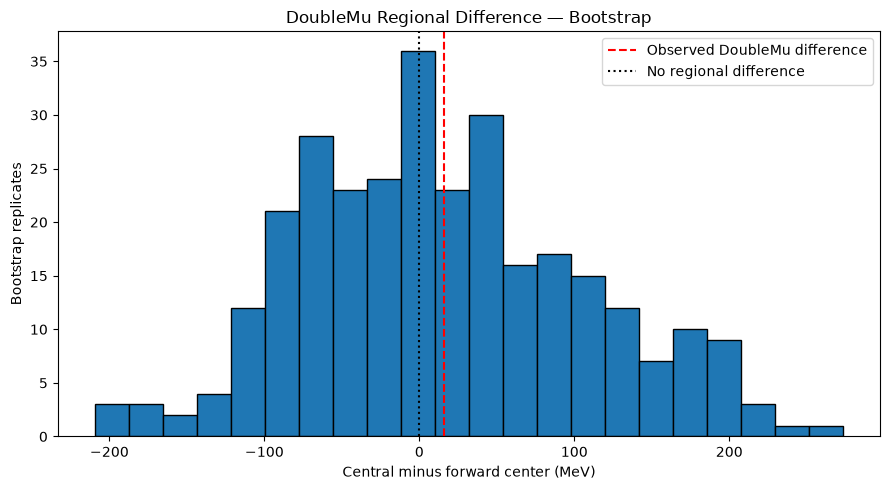

In [43]:

# DoubleMu bootstrap of the regional center difference

from scipy.optimize import minimize
from scipy.special import gammaln
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(3044)

n_bootstrap = 300

regions = [
    "Central-central",
    "Forward-containing"
]

# Use the same baseline window
samples = {}

for region in regions:
    samples[region] = double.loc[
        (double["region"] == region) &
        (double["M_reconstructed"] >= 85) &
        (double["M_reconstructed"] < 97.5),
        "M_reconstructed"
    ].to_numpy()

def bootstrap_fit(sample, region):

    observed, _ = np.histogram(
        sample, bins=edges
    )

    def objective(z):
        mu = expected_doublemu(z * scales)

        if np.any(~np.isfinite(mu)) or np.any(mu <= 0):
            return 1e100

        return np.sum(
            mu - observed * np.log(mu)
            + gammaln(observed + 1)
        )

    initial = doublemu_results[region]["params"].copy()

    # Multiple starts for numerical reliability
    solutions = []

    for sigma0 in [initial[3], 0.8, 1.8]:
        start = initial.copy()
        start[3] = sigma0

        res = minimize(
            objective,
            start / scales,
            method="L-BFGS-B",
            bounds=scaled_bounds,
            options={
                "maxiter": 10000,
                "ftol": 1e-11,
                "maxls": 50
            }
        )

        if res.success and np.isfinite(res.fun):
            solutions.append(res)

    if not solutions:
        return np.nan

    best = min(solutions, key=lambda r: r.fun)

    return (best.x * scales)[1]


differences_double = []

for _ in range(n_bootstrap):

    centers_boot = []

    for region in regions:

        original = samples[region]

        resampled = rng.choice(
            original,
            size=len(original),
            replace=True
        )

        centers_boot.append(
            bootstrap_fit(resampled, region)
        )

    differences_double.append(
        centers_boot[0] - centers_boot[1]
    )

differences_double = np.array(differences_double)

valid_double = differences_double[
    np.isfinite(differences_double)
]

print("Successful fits:", len(valid_double))
print("Failed fits:",
      n_bootstrap - len(valid_double))

if len(valid_double) < 0.95 * n_bootstrap:
    raise RuntimeError("Too many bootstrap fits failed")

observed_double = (
    doublemu_results["Central-central"]["params"][1]
    - doublemu_results["Forward-containing"]["params"][1]
)

print("\nObserved difference (MeV):",
      observed_double * 1000)

print("Bootstrap mean (MeV):",
      valid_double.mean() * 1000)

print("Bootstrap SE (MeV):",
      valid_double.std(ddof=1) * 1000)

print("95% percentile interval (MeV):",
      np.percentile(valid_double, [2.5, 97.5]) * 1000)

plt.figure(figsize=(9, 5))

plt.hist(
    valid_double * 1000,
    bins=22,
    edgecolor="black"
)

plt.axvline(
    observed_double * 1000,
    color="red",
    linestyle="--",
    label="Observed DoubleMu difference"
)

plt.axvline(
    0,
    color="black",
    linestyle=":",
    label="No regional difference"
)

plt.xlabel("Central minus forward center (MeV)")
plt.ylabel("Bootstrap replicates")
plt.title("DoubleMu Regional Difference — Bootstrap")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Cross-Dataset Compatibility Analysis

### Objective

Determine whether the regional resonance-center differences
estimated from SingleMu and DoubleMu are statistically compatible.

### Method

The previously calculated bootstrap distributions are used
to construct a distribution of the difference between
the two regional contrasts.

The datasets have been made nonoverlapping using their
Run and Event identifiers.

A percentile confidence interval is calculated to
assess the uncertainty in the cross-dataset contrast.

### Limitation

The analysis assumes independent sampled events and
retains the original model and fit-window assumptions.
It does not include correlated detector or modeling
systematic uncertainties.

SingleMu bootstrap samples: 499
DoubleMu bootstrap samples: 300

CROSS-DATASET COMPARISON
-----------------------------------
Observed contrast: 150.09 MeV
Bootstrap SE: 109.37 MeV
95% lower limit: -66.53 MeV
95% upper limit: 357.30 MeV
Bootstrap mean: 159.00 MeV


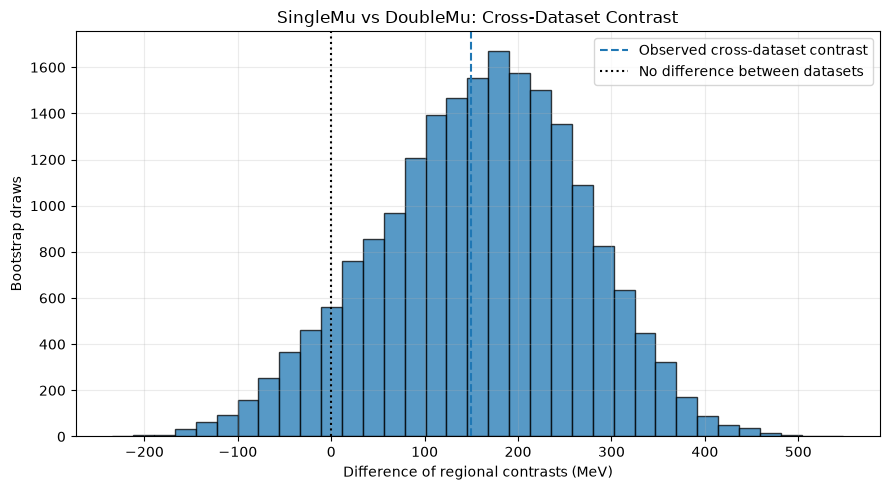

In [46]:

# Cross-dataset bootstrap comparison

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load saved SingleMu bootstrap results from Notebook 02
single_boot_path = (
    PROJECT_ROOT / "results"
    / "regional_bootstrap_500.npy"
)

if not single_boot_path.exists():
    raise FileNotFoundError(
        "SingleMu bootstrap file not found. "
        "Save 'differences' from Notebook 02 as "
        "'results/regional_bootstrap_500.npy'."
    )

single_boot = np.load(single_boot_path)
single_boot = single_boot[np.isfinite(single_boot)]

# DoubleMu bootstrap from Notebook 03
double_boot = np.asarray(differences_double)
double_boot = double_boot[np.isfinite(double_boot)]

print("SingleMu bootstrap samples:", len(single_boot))
print("DoubleMu bootstrap samples:", len(double_boot))

# Observed regional contrasts (GeV)
delta_single = 0.165932
delta_double = (
    doublemu_results["Central-central"]["params"][1]
    - doublemu_results["Forward-containing"]["params"][1]
)

observed_contrast = delta_single - delta_double

# Independently combine the two bootstrap distributions
rng = np.random.default_rng(3045)
n_draws = 20000

single_draws = rng.choice(
    single_boot, size=n_draws, replace=True
)
double_draws = rng.choice(
    double_boot, size=n_draws, replace=True
)

contrast_boot = single_draws - double_draws

se = contrast_boot.std(ddof=1)
ci = np.percentile(contrast_boot, [2.5, 97.5])

print("\nCROSS-DATASET COMPARISON")
print("-" * 35)
print(f"Observed contrast: {observed_contrast*1000:.2f} MeV")
print(f"Bootstrap SE: {se*1000:.2f} MeV")
print(f"95% lower limit: {ci[0]*1000:.2f} MeV")
print(f"95% upper limit: {ci[1]*1000:.2f} MeV")
print(f"Bootstrap mean: {contrast_boot.mean()*1000:.2f} MeV")

# Plot
plt.figure(figsize=(9, 5))

plt.hist(
    contrast_boot * 1000,
    bins=35,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    observed_contrast * 1000,
    linestyle="--",
    label="Observed cross-dataset contrast"
)

plt.axvline(
    0,
    color="black",
    linestyle=":",
    label="No difference between datasets"
)

plt.xlabel("Difference of regional contrasts (MeV)")
plt.ylabel("Bootstrap draws")
plt.title("SingleMu vs DoubleMu: Cross-Dataset Contrast")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


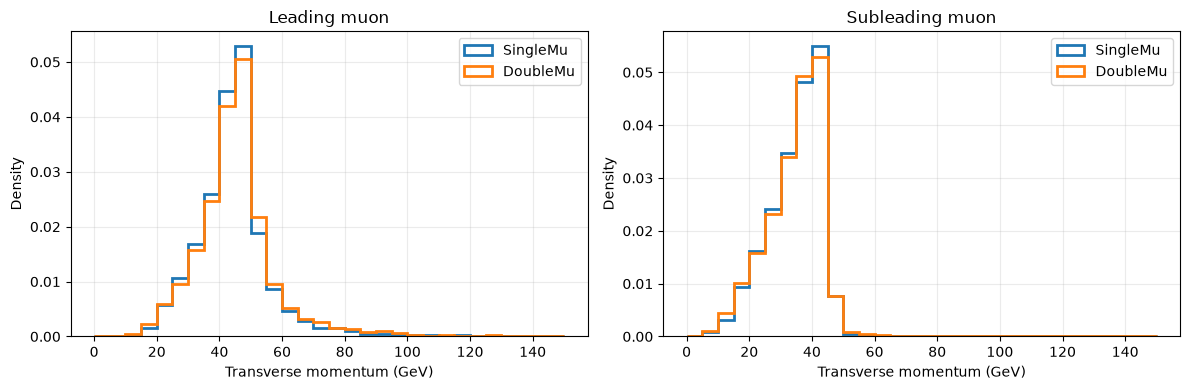

,Dataset,Events,Median leading pT,Median subleading pT,Subleading pT < 20 GeV (%)
0,SingleMu,10179,44.595,36.368,6.641
1,DoubleMu,4656,44.982,36.341,7.818


In [48]:

# Compare leading and subleading muon pT
# within the same Z-resonance fitting window

samples_to_compare = {
    "SingleMu": single_z.copy(),
    "DoubleMu": double_z.copy()
}

summary_rows = []

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, data in samples_to_compare.items():

    leading = data[["pt1", "pt2"]].max(axis=1)
    subleading = data[["pt1", "pt2"]].min(axis=1)

    summary_rows.append({
        "Dataset": name,
        "Events": len(data),
        "Median leading pT": leading.median(),
        "Median subleading pT": subleading.median(),
        "Subleading pT < 20 GeV (%)":
            100 * (subleading < 20).mean()
    })

    for ax, values, title in zip(
        axes,
        [leading, subleading],
        ["Leading muon", "Subleading muon"]
    ):
        ax.hist(
            values,
            bins=np.arange(0, 151, 5),
            density=True,
            histtype="step",
            linewidth=2,
            label=name
        )
        ax.set_title(title)
        ax.set_xlabel("Transverse momentum (GeV)")
        ax.set_ylabel("Density")
        ax.legend()
        ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

pt_summary = pd.DataFrame(summary_rows)
display(pt_summary.round(3))


## 9. Conditional Kinematic Comparison

### Objective

Determine whether SingleMu and DoubleMu contain similar
muon kinematics within the same pseudorapidity categories.

Although the overall leading and subleading transverse-momentum
distributions appear similar, their conditional distributions
may differ.

### Method

Compare central-central and forward-containing events using:

- Leading and subleading muon transverse momentum
- Maximum absolute pseudorapidity
- Proportions satisfying common momentum requirements
- Event counts within the baseline resonance window

No additional event-selection cuts are applied at this stage.

In [51]:
#compare kinematics within detector regions

import numpy as np
import pandas as pd

# Use resonance-window samples from Notebook 03
datasets = {
    "SingleMu": single_z.copy(),
    "DoubleMu": double_z.copy()
}

rows = []

for dataset_name, data in datasets.items():

    data["leading_pt"] = data[["pt1", "pt2"]].max(axis=1)
    data["subleading_pt"] = data[["pt1", "pt2"]].min(axis=1)

    data["max_abs_eta"] = data[
        ["eta1", "eta2"]
    ].abs().max(axis=1)

    for region in [
        "Central-central",
        "Forward-containing"
    ]:

        subset = data[data["region"] == region]

        rows.append({
            "Dataset": dataset_name,
            "Region": region,
            "Events": len(subset),
            "Median leading pT":
                subset["leading_pt"].median(),
            "Median subleading pT":
                subset["subleading_pt"].median(),
            "Median max |eta|":
                subset["max_abs_eta"].median(),
            "Both pT >= 20 (%)":
                100 * (subset["subleading_pt"] >= 20).mean(),
            "Both pT >= 25 (%)":
                100 * (subset["subleading_pt"] >= 25).mean()
        })

conditional_summary = pd.DataFrame(rows)

display(conditional_summary.round(3))


,Dataset,Region,Events,Median leading pT,Median subleading pT,Median max |eta|,Both pT >= 20 (%),Both pT >= 25 (%)
0,SingleMu,Central-central,4073,46.630,39.016,0.829,98.969,95.973
1,SingleMu,Forward-containing,6106,42.193,33.730,1.722,89.617,78.169
2,DoubleMu,Central-central,1854,46.910,38.812,0.832,98.759,94.714
3,DoubleMu,Forward-containing,2802,42.923,33.947,1.684,87.830,77.409


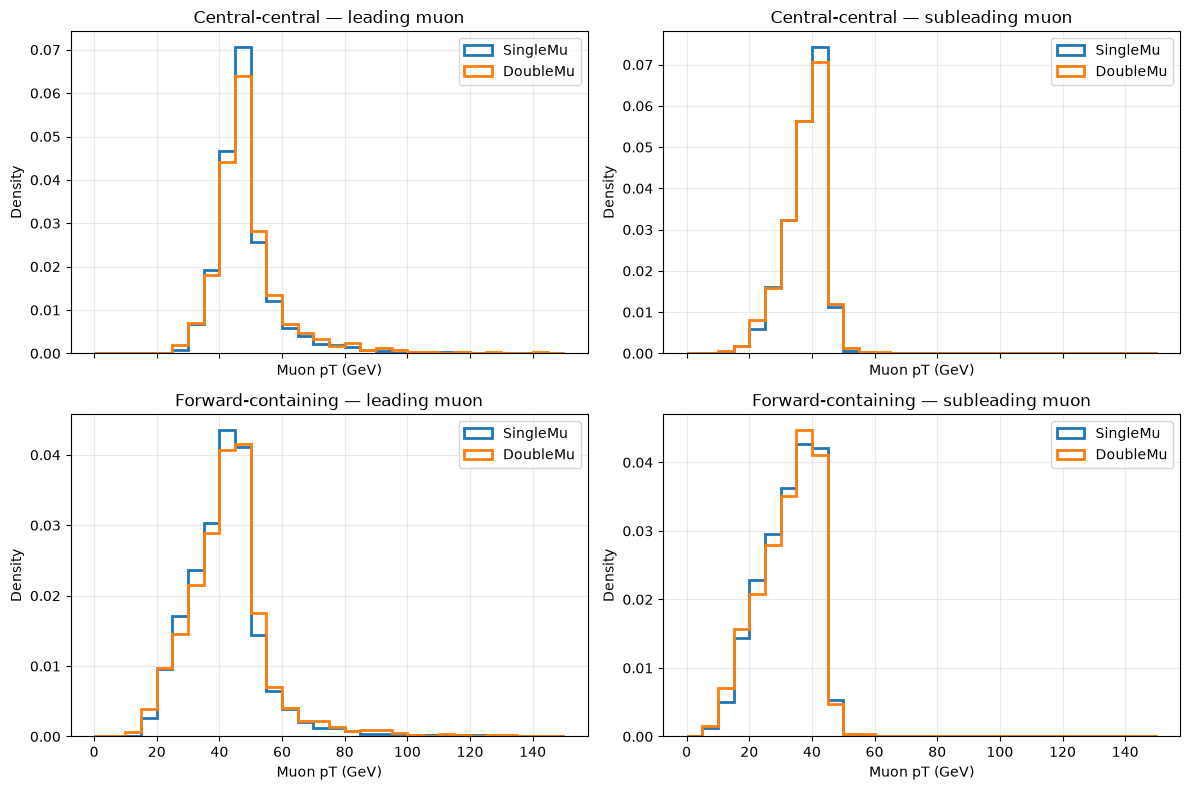

In [53]:
#visualize conditional momentum distribution

import matplotlib.pyplot as plt

regions = [
    "Central-central",
    "Forward-containing"
]

fig, axes = plt.subplots(
    2, 2, figsize=(12, 8),
    sharex="col"
)

for i, region in enumerate(regions):

    for dataset_name, data in datasets.items():

        selected = data[
            data["region"] == region
        ]

        leading = selected["leading_pt"]
        subleading = selected["subleading_pt"]

        axes[i, 0].hist(
            leading,
            bins=np.arange(0, 151, 5),
            density=True,
            histtype="step",
            linewidth=2,
            label=dataset_name
        )

        axes[i, 1].hist(
            subleading,
            bins=np.arange(0, 151, 5),
            density=True,
            histtype="step",
            linewidth=2,
            label=dataset_name
        )

    axes[i, 0].set_title(
        f"{region} — leading muon"
    )

    axes[i, 1].set_title(
        f"{region} — subleading muon"
    )

    for ax in axes[i]:
        ax.set_ylabel("Density")
        ax.set_xlabel("Muon pT (GeV)")
        ax.legend()
        ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 10. Common Transverse-Momentum Selection Study

### Objective

To investigate whether common muon transverse-momentum
requirements alter the regional Z-boson resonance-center
differences in SingleMu and DoubleMu.

### Method

Both datasets are restricted to G-G muon pairs.

Three configurations are compared:

1. No additional transverse-momentum selection.
2. Both muons with pT >= 20 GeV.
3. Both muons with pT >= 25 GeV.

The detector-region definitions, invariant-mass
reconstruction, Voigt-plus-exponential model, fitting
window and histogram bin width remain unchanged.

### Scientific caution

Momentum selections may alter the observed invariant-mass
distribution because momentum and invariant mass are related.

Changes in fitted resonance centers will therefore be
interpreted as selection sensitivity, not automatically
as detector-calibration corrections.

In [56]:

# Section 10: Common pT selection study

import numpy as np
import pandas as pd

datasets = {
    "SingleMu": (single, "M_alt_corrected"),
    "DoubleMu": (double, "M_reconstructed")
}

regions = [
    "Central-central",
    "Forward-containing"
]

thresholds = [None, 20, 25]

selection_results = []
selection_fits = {}

for dataset_name, (data, mass_col) in datasets.items():

    for threshold in thresholds:

        selected = data.copy()

        # Apply common muon pT requirements
        if threshold is not None:
            selected = selected.loc[
                (selected["pt1"] >= threshold) &
                (selected["pt2"] >= threshold)
            ].copy()

        label = (
            "No additional pT cut"
            if threshold is None
            else f"Both pT >= {threshold} GeV"
        )

        fitted = {}

        for region in regions:

            result = fit_selected_sample(
                selected,
                mass_col,
                region
            )

            fitted[region] = result

        central = fitted["Central-central"]
        forward = fitted["Forward-containing"]

        difference = (
            central["center"] - forward["center"]
        )

        selection_fits[(dataset_name, label)] = fitted

        selection_results.append({
            "Dataset": dataset_name,
            "Selection": label,
            "Central N": central["events"],
            "Forward N": forward["events"],
            "Central mass": central["center"],
            "Forward mass": forward["center"],
            "Difference (MeV)": difference * 1000,
            "Central dev/dof": central["deviance_dof"],
            "Forward dev/dof": forward["deviance_dof"]
        })

selection_table = pd.DataFrame(selection_results)

display(selection_table.round(4))


,Dataset,Selection,Central N,Forward N,Central mass,Forward mass,Difference (MeV),Central dev/dof,Forward dev/dof
0,SingleMu,No additional pT cut,3962,5969,90.9859,90.8127,173.1654,1.0623,0.6743
1,SingleMu,Both pT >= 20 GeV,3921,5352,90.9902,90.8124,177.8628,1.0946,0.7676
2,SingleMu,Both pT >= 25 GeV,3802,4664,91.0042,90.8605,143.7562,1.2515,0.7625
3,DoubleMu,No additional pT cut,1828,2762,90.8696,90.8608,8.8546,0.8670,0.7264
4,DoubleMu,Both pT >= 20 GeV,1805,2424,90.8817,90.8719,9.8162,0.8857,0.7312
5,DoubleMu,Both pT >= 25 GeV,1730,2136,90.8757,90.8897,-13.9799,0.7562,0.7793


In [57]:

# Compare regional differences against the
# no-additional-cut G-G baseline

comparison_rows = []

for dataset_name in datasets:

    subset = selection_table.loc[
        selection_table["Dataset"] == dataset_name
    ]

    baseline = subset.loc[
        subset["Selection"] == "No additional pT cut",
        "Difference (MeV)"
    ].iloc[0]

    for _, row in subset.iterrows():

        comparison_rows.append({
            "Dataset": dataset_name,
            "Selection": row["Selection"],
            "Difference (MeV)": row["Difference (MeV)"],
            "Change from baseline (MeV)":
                row["Difference (MeV)"] - baseline
        })

pt_sensitivity = pd.DataFrame(comparison_rows)

display(pt_sensitivity.round(3))


,Dataset,Selection,Difference (MeV),Change from baseline (MeV)
0,SingleMu,No additional pT cut,173.165,0.000
1,SingleMu,Both pT >= 20 GeV,177.863,4.697
2,SingleMu,Both pT >= 25 GeV,143.756,-29.409
3,DoubleMu,No additional pT cut,8.855,0.000
4,DoubleMu,Both pT >= 20 GeV,9.816,0.962
5,DoubleMu,Both pT >= 25 GeV,-13.980,-22.834


## 11. Run-Period Composition Analysis

### Objective

To investigate whether SingleMu and DoubleMu contain
different distributions of events across CMS data-taking
runs.

### Method

The distribution of Run identifiers is compared between
the datasets, focusing on the 85–97.5 GeV resonance window.

The number of common runs and the fraction of events from
shared runs are calculated.

### Interpretation

Differences in run composition may reflect different
data-stream selections or data-taking conditions.

This diagnostic alone cannot establish that run-period
differences cause shifts in the reconstructed resonance.

RUN COVERAGE
----------------------------------------
SingleMu unique runs: 117
DoubleMu unique runs: 15
Common runs: 8


,Dataset,Total Z-window events,Events in shared runs,Shared-run percentage,Unique runs
0,SingleMu,10179,443,4.35,117
1,DoubleMu,4656,2867,61.58,15


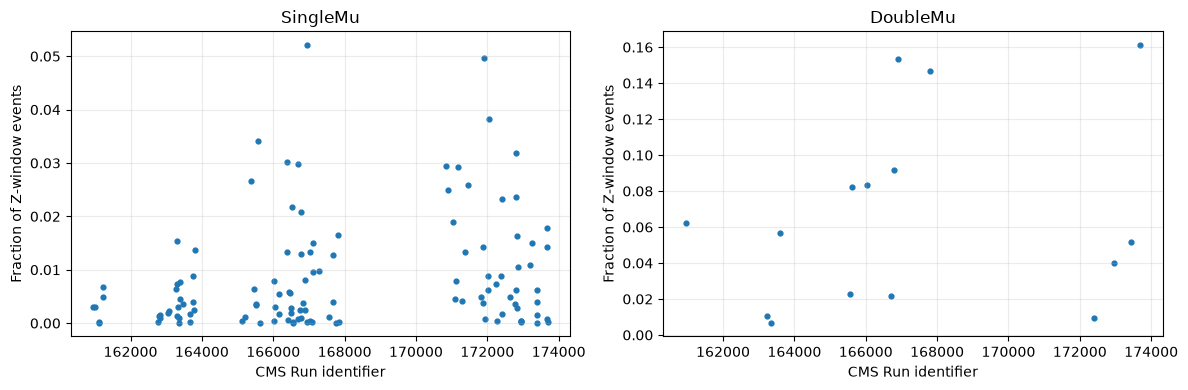

In [61]:
#compare run populations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use existing resonance-window samples
run_samples = {
    "SingleMu": single_z.copy(),
    "DoubleMu": double_z.copy()
}

single_runs = set(single_z["Run"].unique())
double_runs = set(double_z["Run"].unique())

common_runs = single_runs & double_runs

print("RUN COVERAGE")
print("-" * 40)

print("SingleMu unique runs:", len(single_runs))
print("DoubleMu unique runs:", len(double_runs))
print("Common runs:", len(common_runs))

rows = []

for name, data in run_samples.items():

    shared = data["Run"].isin(common_runs)

    rows.append({
        "Dataset": name,
        "Total Z-window events": len(data),
        "Events in shared runs": int(shared.sum()),
        "Shared-run percentage": 100 * shared.mean(),
        "Unique runs": data["Run"].nunique()
    })

run_summary = pd.DataFrame(rows)
display(run_summary.round(2))

# Plot normalized run distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, data) in zip(axes, run_samples.items()):

    counts = data["Run"].value_counts().sort_index()

    ax.scatter(
        counts.index,
        counts.values / counts.values.sum(),
        s=12
    )

    ax.set_title(name)
    ax.set_xlabel("CMS Run identifier")
    ax.set_ylabel("Fraction of Z-window events")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 12. Shared-Run Feasibility Assessment

### Objective

To determine whether SingleMu and DoubleMu contain
sufficient events from common CMS runs for a controlled
regional resonance comparison.

### Method

Events within the baseline 85–97.5 GeV fitting window
are restricted to run identifiers present in both datasets.

Event counts are calculated for central-central and
forward-containing categories, both overall and per run.

No resonance fitting is performed until the available
sample size and model identifiability are assessed.

### Scientific limitation

Common run identifiers do not guarantee identical
trigger selections or detector-response distributions.

In [64]:
#count events by region in shared runs

import pandas as pd
import numpy as np

# Existing resonance-window samples
common_runs = (
    set(single_z["Run"].unique())
    & set(double_z["Run"].unique())
)

single_shared = single_z.loc[
    single_z["Run"].isin(common_runs)
].copy()

double_shared = double_z.loc[
    double_z["Run"].isin(common_runs)
].copy()

print("Number of common runs:", len(common_runs))
print("Common run identifiers:", sorted(common_runs))

print("\nSingleMu — shared-run region counts")
print(single_shared["region"].value_counts())

print("\nDoubleMu — shared-run region counts")
print(double_shared["region"].value_counts())

# Compare each shared run
single_counts = pd.crosstab(
    single_shared["Run"],
    single_shared["region"]
).add_prefix("SingleMu_")

double_counts = pd.crosstab(
    double_shared["Run"],
    double_shared["region"]
).add_prefix("DoubleMu_")

run_region_table = (
    single_counts.join(double_counts, how="outer")
    .fillna(0)
    .astype(int)
)

display(run_region_table)

# Save the result
output_dir = PROJECT_ROOT / "results"
output_dir.mkdir(parents=True, exist_ok=True)

run_region_table.to_csv(
    output_dir / "shared_run_region_counts.csv"
)


Number of common runs: 8
Common run identifiers: [np.int64(160957), np.int64(166033), np.int64(166701), np.int64(166784), np.int64(167807), np.int64(172411), np.int64(172952), np.int64(173692)]

SingleMu — shared-run region counts
region
Forward-containing    261
Central-central       182
Name: count, dtype: int64

DoubleMu — shared-run region counts
region
Forward-containing    1712
Central-central       1155
Name: count, dtype: int64


region,SingleMu_Central-central,SingleMu_Forward-containing,DoubleMu_Central-central,DoubleMu_Forward-containing
Run,,,,
160957,14,17,127,164
166033,39,41,161,226
166701,1,6,38,63
166784,55,77,157,270
167807,66,103,285,397
172411,7,11,10,33
172952,0,4,78,108
173692,0,2,299,451


In [66]:
#acess whether fitting is justified

# Shared-run sample-size diagnostics

rows = []

for name, data in [
    ("SingleMu", single_shared),
    ("DoubleMu", double_shared)
]:

    for region in [
        "Central-central",
        "Forward-containing"
    ]:

        selected = data.loc[data["region"] == region]

        rows.append({
            "Dataset": name,
            "Region": region,
            "Events": len(selected),
            "Runs represented": selected["Run"].nunique(),
            "Mean events per 0.5 GeV bin": len(selected) / 25,
            "Fraction of dataset Z-window (%)": (
                100 * len(selected) /
                len(single_z if name == "SingleMu" else double_z)
            )
        })

feasibility = pd.DataFrame(rows)

display(feasibility.round(2))

print(
    "\nNote: mean count per bin is only a rough"
    " sample-size diagnostic, not a fit-quality criterion."
)


,Dataset,Region,Events,Runs represented,Mean events per 0.5 GeV bin,Fraction of dataset Z-window (%)
0,SingleMu,Central-central,182,6,7.28,1.79
1,SingleMu,Forward-containing,261,8,10.44,2.56
2,DoubleMu,Central-central,1155,8,46.20,24.81
3,DoubleMu,Forward-containing,1712,8,68.48,36.77



Note: mean count per bin is only a rough sample-size diagnostic, not a fit-quality criterion.


## 13. Quantifying Run-Distribution Overlap

The overlap coefficient measures similarity between the
run distributions of the SingleMu and DoubleMu samples.

It is computed for the complete Z-window samples and
separately for the two detector-region categories.

The coefficient describes sample composition, not
detector calibration or physical resonance differences.

,Comparison,Overlap,Overlap (%)
0,All Z-window events,0.0435,4.3521
1,Central-central,0.0447,4.4685
2,Forward-containing,0.0427,4.2745


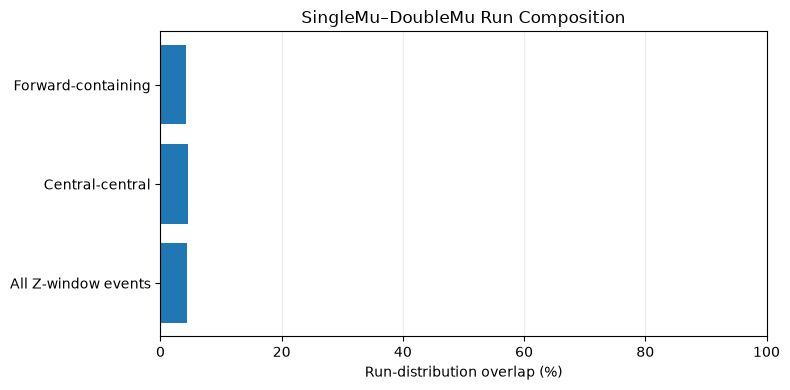

In [69]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def run_overlap(a, b):
    p = a["Run"].value_counts(normalize=True)
    q = b["Run"].value_counts(normalize=True)

    runs = p.index.union(q.index)

    p = p.reindex(runs, fill_value=0)
    q = q.reindex(runs, fill_value=0)

    overlap = np.minimum(p, q).sum()

    return float(overlap)

rows = [{
    "Comparison": "All Z-window events",
    "Overlap": run_overlap(single_z, double_z)
}]

for region in [
    "Central-central",
    "Forward-containing"
]:
    a = single_z.loc[single_z["region"] == region]
    b = double_z.loc[double_z["region"] == region]

    rows.append({
        "Comparison": region,
        "Overlap": run_overlap(a, b)
    })

overlap_table = pd.DataFrame(rows)
overlap_table["Overlap (%)"] = 100 * overlap_table["Overlap"]

display(overlap_table.round(4))

fig, ax = plt.subplots(figsize=(8, 4))

ax.barh(
    overlap_table["Comparison"],
    overlap_table["Overlap (%)"]
)

ax.set_xlabel("Run-distribution overlap (%)")
ax.set_xlim(0, 100)
ax.set_title("SingleMu–DoubleMu Run Composition")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

# Save reproducible result
output_dir = PROJECT_ROOT / "results"
output_dir.mkdir(parents=True, exist_ok=True)

overlap_table.to_csv(
    output_dir / "run_distribution_overlap.csv",
    index=False
)



## 14. DoubleMu Kinematic-Consistency Sensitivity

### Objective

Determine whether the inconsistency between stored and
Cartesian-reconstructed transverse momenta materially
affects the fitted Z-resonance centers.

### Method

Repeat the baseline regional Voigt-plus-exponential fits
with and without events exceeding a 0.01 GeV transverse-
momentum consistency threshold.

The original nonoverlapping DoubleMu sample is retained
as the primary analysis.

All fitting settings remain unchanged.

### Interpretation

This is a sensitivity test, not a detector-quality
calibration or an official CMS event-selection criterion.


In [72]:

# Section 14 — DoubleMu kinematic consistency

import numpy as np
import pandas as pd

# Use the nonoverlapping DoubleMu sample
double_quality = df_rep.copy()

for i in [1, 2]:
    pt_cartesian = np.hypot(
        double_quality[f"px{i}"],
        double_quality[f"py{i}"]
    )

    double_quality[f"pt{i}_difference"] = (
        double_quality[f"pt{i}"] - pt_cartesian
    ).abs()

double_quality["pt_inconsistent"] = (
    (double_quality["pt1_difference"] > 0.01) |
    (double_quality["pt2_difference"] > 0.01)
)

in_window = double_quality["M_reconstructed"].between(
    85, 97.5, inclusive="left"
)

print("Nonoverlapping DoubleMu events:", len(double_quality))

print("\nEvents in fit window:")
print(in_window.sum())

print("\nFlagged events by region:")
quality_counts = pd.crosstab(
    double_quality.loc[in_window, "region"],
    double_quality.loc[in_window, "pt_inconsistent"]
)

display(quality_counts)


Nonoverlapping DoubleMu events: 99901

Events in fit window:
4656

Flagged events by region:


pt_inconsistent,False,True
region,,
Central-central,1839,15
Forward-containing,2789,13


In [74]:

from scipy.optimize import minimize
from scipy.special import gammaln

def refit_quality_sample(data, region):

    masses = data.loc[
        data["region"] == region,
        "M_reconstructed"
    ].dropna().to_numpy()

    observed, _ = np.histogram(masses, bins=edges)

    def nll(z):
        predicted = expected_doublemu(z * scales)

        if np.any(~np.isfinite(predicted)) or np.any(predicted <= 0):
            return 1e100

        return np.sum(
            predicted - observed * np.log(predicted)
            + gammaln(observed + 1)
        )

    base = doublemu_results[region]["params"].copy()
    solutions = []

    for center_start in [base[1], 90.5, 91.0]:
        for sigma_start in [base[3], 0.8, 1.8]:
            start = base.copy()
            start[1] = center_start
            start[3] = sigma_start

            result = minimize(
                nll,
                start / scales,
                method="L-BFGS-B",
                bounds=scaled_bounds,
                options={
                    "maxiter": 15000,
                    "ftol": 1e-12,
                    "maxls": 50
                }
            )

            if result.success and np.isfinite(result.fun):
                solutions.append(result)

    if not solutions:
        raise RuntimeError(f"Fit failed for {region}")

    best = min(solutions, key=lambda r: r.fun)
    fitted = best.x * scales
    predicted = expected_doublemu(fitted)

    nonzero = observed > 0
    terms = np.zeros(len(observed))

    terms[nonzero] = (
        observed[nonzero] *
        np.log(observed[nonzero] / predicted[nonzero])
    )

    deviance = 2 * np.sum(
        terms - (observed - predicted)
    )

    return {
        "center": fitted[1],
        "events": int(observed.sum()),
        "deviance_dof": deviance / (len(observed) - len(fitted))
    }


results_quality = []

for label, data in [
    ("All events", double_quality),
    (
        "Consistency-filtered",
        double_quality.loc[
            ~double_quality["pt_inconsistent"]
        ].copy()
    )
]:
    central = refit_quality_sample(data, "Central-central")
    forward = refit_quality_sample(data, "Forward-containing")

    results_quality.append({
        "Sample": label,
        "Central N": central["events"],
        "Forward N": forward["events"],
        "Central center (GeV)": central["center"],
        "Forward center (GeV)": forward["center"],
        "Regional difference (MeV)":
            1000 * (central["center"] - forward["center"]),
        "Central dev/dof": central["deviance_dof"],
        "Forward dev/dof": forward["deviance_dof"]
    })

quality_sensitivity = pd.DataFrame(results_quality)

display(quality_sensitivity.round(5))

shift = (
    quality_sensitivity.iloc[1]["Regional difference (MeV)"]
    - quality_sensitivity.iloc[0]["Regional difference (MeV)"]
)

print(f"\nChange in regional difference: {shift:+.3f} MeV")


,Sample,Central N,Forward N,Central center (GeV),Forward center (GeV),Regional difference (MeV),Central dev/dof,Forward dev/dof
0,All events,1854,2802,90.87434,90.85849,15.84284,0.79941,0.76542
1,Consistency-filtered,1839,2789,90.85884,90.86946,-10.62027,0.86303,0.77287



Change in regional difference: -26.463 MeV


In [76]:
#saving the results 

# Save DoubleMu quality-sensitivity results

from pathlib import Path

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

quality_sensitivity.to_csv(
    RESULTS_DIR / "doublemu_quality_sensitivity.csv",
    index=False
)

# Compare against the original regional difference
baseline = quality_sensitivity.iloc[0]
filtered = quality_sensitivity.iloc[1]

print("DATA-QUALITY SENSITIVITY SUMMARY")
print("-" * 40)

print(
    "Excluded events:",
    int(
        baseline["Central N"] + baseline["Forward N"]
        - filtered["Central N"] - filtered["Forward N"]
    )
)

print(
    "Regional difference before filtering (MeV):",
    round(baseline["Regional difference (MeV)"], 3)
)

print(
    "Regional difference after filtering (MeV):",
    round(filtered["Regional difference (MeV)"], 3)
)

print(
    "Change (MeV):",
    round(
        filtered["Regional difference (MeV)"]
        - baseline["Regional difference (MeV)"],
        3
    )
)

print("\nResults saved successfully.")


DATA-QUALITY SENSITIVITY SUMMARY
----------------------------------------
Excluded events: 28
Regional difference before filtering (MeV): 15.843
Regional difference after filtering (MeV): -10.62
Change (MeV): -26.463

Results saved successfully.



## 15. Fixed-Width Voigt Model Sensitivity

### Objective

Investigate whether the fitted regional Z-resonance
centers depend on allowing the Lorentzian width parameter
to vary freely.

### Method

Compare two Voigt-plus-exponential background models:

1. Free-width model: gamma is fitted.
2. Fixed-width model: gamma = 1.24775 GeV.

All other model parameters are reoptimized.

The same mass window (85–97.5 GeV), bin width
(0.5 GeV), and Poisson maximum-likelihood method
are retained.

### Hypothesis

If the fitted resonance centers change substantially
after fixing gamma, this indicates sensitivity to the
resonance-width parameterization.

### Limitation

The Lorentzian approximation does not fully represent
the physical Z-boson line shape, including effects such
as final-state radiation and mass-dependent widths.


In [79]:
#fit both data sets with fixed gamma

import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import gammaln

GAMMA_FIXED = 1.24775  # GeV, Lorentzian HWHM

regions = [
    "Central-central",
    "Forward-containing"
]

datasets_fixed = {
    "SingleMu": (single, "M_alt_corrected"),
    "DoubleMu": (double, "M_reconstructed")
}

def fit_fixed_gamma(data, mass_col, region):

    mass = data.loc[
        data["region"] == region,
        mass_col
    ].dropna().to_numpy()

    observed, _ = np.histogram(
        mass, bins=edges
    )

    # Five free parameters:
    # S, m0, sigma, B0, k

    free_indices = [0, 1, 3, 4, 5]

    free_scales = scales[free_indices]

    free_bounds = [
        scaled_bounds[i] for i in free_indices
    ]

    def full_params(z):
        p = np.zeros(6)
        p[free_indices] = z * free_scales
        p[2] = GAMMA_FIXED
        return p

    def nll(z):
        predicted = expected_doublemu(
            full_params(z)
        )

        if np.any(~np.isfinite(predicted)) or np.any(predicted <= 0):
            return 1e100

        return np.sum(
            predicted
            - observed * np.log(predicted)
            + gammaln(observed + 1)
        )

    solutions = []

    for center0 in [90.5, 91.0, 91.5]:
        for sigma0 in [0.8, 1.2, 1.8]:

            start = np.array([
                3000, center0, sigma0, 50, -0.15
            ])

            result = minimize(
                nll,
                start / free_scales,
                method="L-BFGS-B",
                bounds=free_bounds,
                options={
                    "maxiter": 20000,
                    "ftol": 1e-12,
                    "maxls": 50
                }
            )

            if result.success and np.isfinite(result.fun):
                solutions.append(result)

    if not solutions:
        raise RuntimeError(
            f"Fixed-gamma fit failed: {region}"
        )

    best = min(solutions, key=lambda r: r.fun)
    params = full_params(best.x)
    predicted = expected_doublemu(params)

    positive = observed > 0
    terms = np.zeros(len(observed), dtype=float)

    terms[positive] = (
        observed[positive] *
        np.log(observed[positive] / predicted[positive])
    )

    deviance = 2 * np.sum(
        terms - (observed - predicted)
    )

    dof = len(observed) - 5

    return {
        "params": params,
        "center": params[1],
        "sigma": params[3],
        "gamma": params[2],
        "nll": best.fun,
        "deviance_dof": deviance / dof,
        "events": int(observed.sum())
    }


fixed_results = {}
fixed_summary = []

for dataset_name, (data, mass_col) in datasets_fixed.items():

    fixed_results[dataset_name] = {}

    for region in regions:

        result = fit_fixed_gamma(
            data, mass_col, region
        )

        fixed_results[dataset_name][region] = result

        fixed_summary.append({
            "Dataset": dataset_name,
            "Region": region,
            "Events": result["events"],
            "Center (GeV)": result["center"],
            "Gamma fixed (GeV)": result["gamma"],
            "Sigma (GeV)": result["sigma"],
            "Deviance/dof": result["deviance_dof"]
        })

fixed_summary = pd.DataFrame(fixed_summary)

display(fixed_summary.round(5))

# Calculate regional differences
for dataset_name in datasets_fixed:

    central = fixed_results[
        dataset_name
    ]["Central-central"]["center"]

    forward = fixed_results[
        dataset_name
    ]["Forward-containing"]["center"]

    print(
        f"{dataset_name} fixed-gamma regional difference:",
        round(1000 * (central-forward), 3),
        "MeV"
    )


,Dataset,Region,Events,Center (GeV),Gamma fixed (GeV),Sigma (GeV),Deviance/dof
0,SingleMu,Central-central,4073,90.98862,1.24775,0.98666,0.95353
1,SingleMu,Forward-containing,6106,90.80621,1.24775,1.31774,0.68795
2,DoubleMu,Central-central,1854,90.86398,1.24775,1.11497,0.76729
3,DoubleMu,Forward-containing,2802,90.86353,1.24775,1.30722,0.72909


SingleMu fixed-gamma regional difference: 182.411 MeV
DoubleMu fixed-gamma regional difference: 0.449 MeV


In [81]:
#compare against free width fits

# Compare free- and fixed-gamma regional contrasts

baseline_differences = {
    "SingleMu": 165.932,
    "DoubleMu": 15.843
}

comparison = []

for dataset_name in datasets_fixed:

    central = fixed_results[
        dataset_name
    ]["Central-central"]["center"]

    forward = fixed_results[
        dataset_name
    ]["Forward-containing"]["center"]

    fixed_difference = 1000 * (central - forward)

    comparison.append({
        "Dataset": dataset_name,
        "Free-gamma difference (MeV)":
            baseline_differences[dataset_name],
        "Fixed-gamma difference (MeV)":
            fixed_difference,
        "Change (MeV)":
            fixed_difference - baseline_differences[dataset_name]
    })

fixed_comparison = pd.DataFrame(comparison)

display(fixed_comparison.round(3))


,Dataset,Free-gamma difference (MeV),Fixed-gamma difference (MeV),Change (MeV)
0,SingleMu,165.932,182.411,16.479
1,DoubleMu,15.843,0.449,-15.394


In [83]:
#checking fixed width quantity

# Compare fixed-width fit quality and check parameter bounds

import numpy as np
import pandas as pd

rows = []

# Physical parameter indices:
# S, m0, gamma, sigma, B0, k
free_indices = [0, 1, 3, 4, 5]

for dataset_name, regional_fits in fixed_results.items():
    for region, result in regional_fits.items():

        params = np.asarray(result["params"])

        # Check whether a freely fitted parameter
        # is very close to a bound.
        near_bounds = []

        for i in free_indices:
            lo, hi = bounds[i]
            tolerance = 0.001 * (hi - lo)

            if (
                params[i] - lo <= tolerance
                or hi - params[i] <= tolerance
            ):
                near_bounds.append(
                    ["S", "m0", "sigma", "B0", "k"][free_indices.index(i)]
                )

        rows.append({
            "Dataset": dataset_name,
            "Region": region,
            "Center (GeV)": params[1],
            "Sigma (GeV)": params[3],
            "Background slope": params[5],
            "Deviance/dof": result["deviance_dof"],
            "Near bounds": ", ".join(near_bounds) if near_bounds else "None"
        })

fixed_diagnostics = pd.DataFrame(rows)

display(fixed_diagnostics.round(5))

fixed_diagnostics.to_csv(
    PROJECT_ROOT / "results" / "fixed_width_diagnostics.csv",
    index=False
)


,Dataset,Region,Center (GeV),Sigma (GeV),Background slope,Deviance/dof,Near bounds
0,SingleMu,Central-central,90.98862,0.98666,-0.30566,0.95353,None
1,SingleMu,Forward-containing,90.80621,1.31774,-0.20202,0.68795,None
2,DoubleMu,Central-central,90.86398,1.11497,-0.25262,0.76729,None
3,DoubleMu,Forward-containing,90.86353,1.30722,-0.18253,0.72909,None


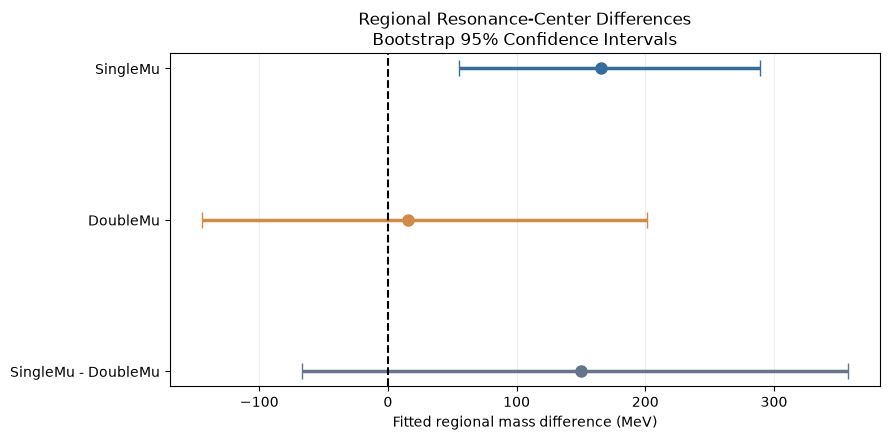

In [85]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

labels = [
    "SingleMu",
    "DoubleMu",
    "SingleMu - DoubleMu"
]

estimate = np.array([
    165.93, 15.84, 150.09
])

ci_low = np.array([
    55.47, -144.45, -66.53
])

ci_high = np.array([
    288.78, 201.12, 357.30
])

lower_error = estimate - ci_low
upper_error = ci_high - estimate

y = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(9, 4.5))

colors = ["#356D9D", "#D18B47", "#64748B"]

for i in range(len(labels)):
    ax.errorbar(
        estimate[i],
        y[i],
        xerr=np.array([
            [lower_error[i]],
            [upper_error[i]]
        ]),
        fmt="o",
        color=colors[i],
        markersize=8,
        capsize=6,
        linewidth=2.5
    )

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5
)

ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.invert_yaxis()

ax.set_xlabel(
    "Fitted regional mass difference (MeV)"
)

ax.set_title(
    "Regional Resonance-Center Differences\n"
    "Bootstrap 95% Confidence Intervals"
)

ax.grid(axis="x", alpha=0.2)

fig.tight_layout()

out = Path("../figures")
out.mkdir(exist_ok=True, parents=True)

fig.savefig(
    out / "regional_difference_validation.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    out / "regional_difference_validation.pdf",
    bbox_inches="tight"
)

plt.show()
